# Natural frequencies of cylinders with four and eight channel stringers: Egle and Sewall (1968)

Egle and Sewall [1] developed a Rayleigh-Ritz vibration analysis of
stiffened cylinders in which each stringer is a discrete beam, and applied
it to two steel cylinders with few stringers: four and eight equally spaced
internal stringers of open (channel, "hat-shaped") section, freely
supported. With few stringers the circumferential modes of different wave
numbers $n$ couple, and each wave number gives two frequencies, one for the
modes symmetric and one for the modes antisymmetric about the plane of a
stringer [1] (pages 521 and 522). Their Table 3 (page 524) lists the
frequencies of the four-stringer cylinder for both families and of the same
cylinder without stringers; their Figures 3 and 4 (page 523) compare their
analysis with the tests of Schnell and Heinrichsbauer (Ref. 8 of [1]) on
the four- and eight-stringer cylinders. Sewall and Naumann [2] (Figure 12,
report page 52, and page 20) compare the same eight-stringer tests (their
Ref. 15) with their analysis with the stringers averaged ("smeared") over
the skin, including the eccentricity of the stringers ("Present paper"),
and with the equivalent orthotropic shell of their Ref. 13 and Appendix B,
which does not account for the eccentricity explicitly.

Here both cylinders, and the cylinder without stringers, are modelled with
discrete stringers assembled from plates:

- the skin with the BFSC cylinder element of Sanders-type kinematics,
  `BFSCCylinderSanders`;
- each channel with BFSC plate elements `BFSCPlate2D` of
  [bfscplate2d](https://github.com/saullocastro/bfscplate2d): two webs
  normal to the skin and two lips, bent at 90 degrees at the free edges of
  the webs; the base of the channel, which lies on the skin, is a second
  layer of the skin elements under it.

One stringer pitch with cyclic symmetry represents the cylinder; each mode
is then classified, as in [1], by the largest term of the Fourier series of
its normal displacement around the circumference and by its symmetry about
the plane of a stringer. The natural frequencies of the problem
$(\boldsymbol{K}_{C0} - \omega^2 \boldsymbol{M})\boldsymbol{u} =
\boldsymbol{0}$ are compared with every value of Table 3 of [1], with the
theory and the tests of Figures 3 and 4 of [1] and with the tests and both
smeared analyses of Figure 12 of [2], all digitised.

The model is given by the module `channel_cylinder_sector.py`, next to this
notebook. Besides `bfsccylinder`, it needs `bfscplate2d`, `composites`, SciPy
and Matplotlib. The digitised values are in the folder `results/`.

**References**

[1] Egle, D. M.; Sewall, J. L., "An analysis of free vibration of
orthogonally stiffened cylindrical shells with stiffeners treated as
discrete elements", AIAA Journal 6(3), 518-526, 1968.
https://doi.org/10.2514/3.4528

[2] Sewall, J. L.; Naumann, E. C., "An experimental and analytical
vibration study of thin cylindrical shells with and without longitudinal
stiffeners", NASA TN D-4705, September 1968.
https://ntrs.nasa.gov/citations/19680024266

The tests are those of Schnell, W. and Heinrichsbauer, F. J., "The
determination of free vibrations of longitudinally-stiffened thin-walled,
circular cylindrical shells", NASA TT F-8856, April 1964 (Ref. 8 of [1],
Ref. 15 of [2]), which was not consulted: every test value below is read
from the figures of [1] and [2].

In [1]:
%matplotlib inline
import csv
import os
import time
from multiprocessing import Pool

import numpy as np
import matplotlib.pyplot as plt

from bfsccylinder.version import __version__ as bfsccylinder_version
from bfscplate2d.version import __version__ as bfscplate2d_version
from channel_cylinder_sector import (ChannelCylinderSector, TwoLayerSkin,
                                     solve_case, table, section_properties,
                                     normalize_phase, DOF, U, V, W)

print('bfsccylinder', bfsccylinder_version)
print('bfscplate2d', bfscplate2d_version)

bfsccylinder 0.7.1
bfscplate2d 0.5.0


## Geometry and material

Table 1 of [1] (page 522), "4 and 8 stringer case", in inches, pounds-force
and seconds; the stringer properties are "taken from Ref. 8, open profile
stringers", and the transverse stiffening of the skin by the stringers is
not included, $D_x/D = D_y/D = 1$. Figure 12 of [2] (report page 52) gives
the same cylinder rounded, $R$ = 7.65 in, $h$ = 0.0183 in, $L$ = 38.85 in,
and the "stiffener detail": a channel of thickness 0.014 in (0.35 mm), its
base on the skin, 0.197 in (5.00 mm) wide over the outer faces of the webs,
0.394 in (10.00 mm) from the inner surface of the base to the top of the
lips, and lips of 0.098 in (2.50 mm) outside the webs, pointing away from
the channel. Page 20 of [2] says that the models were made of 0.0183 in
sheet steel and that the stringers are of "hat-shaped cross section".

In [2]:
# Table 1 of [1], page 522 (4 and 8 stringer case); in, lbf, s
R = 7.657        # in
L = 38.85        # in, a of [1]
h = 1.826e-2     # in
E = 29.0e6       # psi, shell and stringers
rho = 7.34e-4    # lbf s^2/in^4
nu = 0.30
G = E/(2*(1 + nu))
table1 = dict(A=1.627e-2, zbar=-0.2082, d=0.2576, p=0.2750, GJ=11.31)

# stringer detail of Figure 12 of [2], report page 52; in
t = 0.014        # thickness of the channel
b_out = 0.197    # over the outer faces of the webs
web_in = 0.394   # inner surface of the base to the top of the lips
lip_out = 0.098  # lip, outside the outer face of the web

## Stringer section

**Middle lines of the drawing.** With $z$ along the outward normal from
the middle surface of the skin (the stringers are inside, $z < 0$), the
middle surface of the base is at $z_b = -(h/2 + t/2)$ and that of the lips
at $z_l = z_b - 0.394$ in; the webs are $b = 0.197 - t$ apart (middle
surfaces) and a lip is $b_l = 0.098 + t/2$ wide from the middle surface of
its web. The section of the drawing is then three rectangles of
thickness $t$ along these middle lines (base $b$, webs $|z_l - z_b|$, lips
$b_l$).

**Model.** The plate of a web is tied to the skin along its root, on the
middle surface of the skin (the nodes of the BFSC elements have no offset),
so that it goes from $z = 0$ to $z_l$, $H_w = |z_l|$ high: it overlaps the
skin and the base over $h/2 + t/2$. The lips are plates of width $b_l$ at
$z_l$. The base is **not** a plate: a plate parallel to the skin, offset by
$-(h/2 + t/2)$, would need its axial displacement tied to $u - z\,w_{,x}$
of the skin, and the derivative of this tie along $x$, needed by the degree
of freedom $u_{,x}$ of the BFSC elements, contains $w_{,xx}$, which is not a
degree of freedom; a plate on the middle surface would lose its
eccentricity. Instead the skin elements between the two webs are a
laminate of two layers, the skin and the base, with the stiffnesses
$\boldsymbol{A}$, $\boldsymbol{B}$, $\boldsymbol{D}$ about the middle surface
of the skin, which is exact for a base bonded to the skin over its whole
width, and the mass of both layers (the mass matrix of the element has no
eccentricity: the offset of the mass of the base, 0.016 in, is neglected).

The properties of both sections against Table 1 of [1]: the area $A_s$, the
centroid $\bar{z}_s$, the radius of gyration $d_s'$ for bending in the
plane $(x, r)$, the polar radius of gyration $p_s'$ and the torsional
stiffness $(GJ)_s$, with the radii both about the centroid and about the
middle surface of the skin (and the point of it under the stringer). The
torsional stiffness is that of the thin rectangles, $G \sum b t^3/3$, the
base included (in the model the base works in the laminate with the skin).

In [3]:
zb = -(h/2 + t/2)        # middle surface of the base
zl = zb - web_in         # middle surface of the lips
b = b_out - t            # between the middle surfaces of the webs
bl = lip_out + t/2       # lip, from the middle surface of the web
Hw = -zl                 # web plates of the model, from the skin middle surface
drawing = [(0., zb, b, t), (-b/2, (zb + zl)/2, t, web_in),
           (b/2, (zb + zl)/2, t, web_in), (-(b + bl)/2, zl, bl, t),
           ((b + bl)/2, zl, bl, t)]
model_section = [(0., zb, b, t), (-b/2, zl/2, t, Hw), (b/2, zl/2, t, Hw),
                 (-(b + bl)/2, zl, bl, t), ((b + bl)/2, zl, bl, t)]
sec = {'drawing': section_properties(drawing, G),
       'model': section_properties(model_section, G)}
print('b = %.4f in, b_l = %.4f in, z_b = %.5f in, z_l = %.5f in, H_w = %.5f in'
      % (b, bl, zb, zl, Hw))
rows = [('A_s (in^2)', 'A', table1['A']),
        ('z_s (in), from the skin middle surface', 'zbar', table1['zbar']),
        ('d_s about the centroid (in)', 'dc', table1['d']),
        ('d_s about the skin middle surface (in)', 'd0', table1['d']),
        ('p_s about the centroid (in)', 'pc', table1['p']),
        ('p_s about the skin middle surface (in)', 'p0', table1['p']),
        ('(GJ)_s (lbf in^2)', 'GJ', table1['GJ'])]
print('\n%-40s %10s | %10s %7s | %10s %7s' % ('', 'Table 1', 'drawing',
                                             'diff', 'model', 'diff'))
for label, key, ref in rows:
    a, m = sec['drawing'][key], sec['model'][key]
    print('%-40s %10.5g | %10.5g %+6.1f%% | %10.5g %+6.1f%%'
          % (label, ref, a, 100*(a/ref - 1), m, 100*(m/ref - 1)))
print('\nz_s of the drawing from the inner surface of the skin: %.4f in'
      % (sec['drawing']['zbar'] + h/2))
for key in ['drawing', 'model']:
    s = sec[key]
    print('%-8s E I0 = %.4g lbf in^2, E A d_s^2 of Table 1 (d_s about the '
          'skin) = %.4g lbf in^2' % (key, E*s['I0'], E*table1['A']*table1['d']**2))

b = 0.1830 in, b_l = 0.1050 in, z_b = -0.01613 in, z_l = -0.41013 in, H_w = 0.41013 in

                                            Table 1 |    drawing    diff |      model    diff
A_s (in^2)                                  0.01627 |   0.016534   +1.6% |   0.016986   +4.4%
z_s (in), from the skin middle surface      -0.2082 |   -0.21763   +4.5% |   -0.21206   +1.9%
d_s about the centroid (in)                  0.2576 |    0.14673  -43.0% |    0.14865  -42.3%
d_s about the skin middle surface (in)       0.2576 |    0.26248   +1.9% |    0.25897   +0.5%
p_s about the centroid (in)                   0.275 |    0.17723  -35.6% |    0.17871  -35.0%
p_s about the skin middle surface (in)        0.275 |    0.28067   +2.1% |    0.27732   +0.8%
(GJ)_s (lbf in^2)                             11.31 |     12.049   +6.5% |     12.378   +9.4%

z_s of the drawing from the inner surface of the skin: -0.2085 in
drawing  E I0 = 3.303e+04 lbf in^2, E A d_s^2 of Table 1 (d_s about the skin) = 3.131e+04 lbf

The section of the drawing has an area 1.6 % larger than $A_s$ of Table 1.
The radii of gyration of Table 1 match those of the drawing **about the
middle surface of the skin** (within 2 %), not about the centroid (35 to
43 % smaller), although the nomenclature of [1] (page 518) defines
$d_s'$ about a centroidal axis; the strain energy of the stringers of [1],
Eq. (5) (page 519), with the terms $u_{,x}^2 - 2\bar{z} u_{,x} w_{,xx} +
(d'_s)^2 w_{,xx}^2$, does need $d_s'$ about the middle surface of the skin,
so Table 1 is consistent with Eq. (5). The centroid of Table 1, 0.2082 in,
matches the distance of the centroid of the drawing from the inner surface
of the skin, 0.2085 in, rather than from its middle surface, 0.2176 in.

The section of the model is larger than the drawing by the overlap of the
webs with the skin and the base: $A_s$ +4.4 % and $E I_0$ +5.5 % against
Table 1. These are small against the skin: the four (eight) stringers add
7.7 % (15.5 %) to the mass of the skin.

The laminate of the skin under the base, against the skin alone:

In [4]:
skin = TwoLayerSkin(h, 0., E, nu)
lam = TwoLayerSkin(h, t, E, nu, side='internal')
for k in ['A11', 'A66', 'B11', 'D11', 'D66']:
    print('%s: skin %10.4g, skin + base %10.4g' % (k, getattr(skin, k),
                                                     getattr(lam, k)))

A11: skin  5.819e+05, skin + base  1.028e+06
A66: skin  2.037e+05, skin + base  3.598e+05
B11: skin          0, skin + base      -7196
D11: skin      16.17, skin + base      139.5
D66: skin      5.659, skin + base      48.84


## Model: one stringer pitch with cyclic symmetry

The sector $0 \le \theta \le \phi = 2\pi/n_s$ has the channel at its middle,
$\theta_c = \phi/2$, and the edges of the sector halfway between two
stringers. Across the sector the skin has `nbay` elements from each edge to
the nearest web, graded (the largest three times the smallest, the smallest
next to the web), and two laminate elements under the base, between the two
webs; along $x$, `nx` nodes. Each web has `nweb` elements along its height,
each lip `nlip` elements across. The webs are tied to the skin and the lips
to the webs as rigid joints (the ties are written in the docstring of the
module): the channel is assumed bonded to the skin along the two lines of
the webs and over the base.

**Cyclic symmetry.** The degrees of freedom of the sector $k$ of a mode are
those of the sector 0 multiplied by $e^{i j k \phi}$; the nodes of the edge
$\theta = \phi$ are eliminated with $\boldsymbol{u}(\phi) = e^{i j
\phi}\boldsymbol{u}(0)$, which gives one Hermitian eigenvalue problem per
Bloch index $j = 0, 1, \ldots, n_s/2$. A Bloch index contains every
circumferential wave number $n = |j + k n_s|$ ($k$ integer): with
$n_s = 4$, $j = 0$ contains $n$ = 0, 4, 8, 12, ..., $j = 1$ contains $n$ =
1, 3, 5, 7, ..., $j = 2$ contains $n$ = 2, 6, 10, .... This is the coupling
rule of [1], Eq. (13) (page 522): harmonics $n$ and $n'$ are coupled when
$n \pm n'$ is a multiple of $n_s$.

**Symmetric and antisymmetric modes.** The cylinder is also symmetric about
the plane of each stringer. For $j = 0$ and $j = n_s/2$ the problem is real
and each mode is either symmetric or antisymmetric about that plane, with
different frequencies: these are the even $n$ for $n_s = 4$ (stringers at
the antinodes or at the nodes of $\cos n\theta$). For $0 < j < n_s/2$ the
problem is complex and each eigenvalue is a pair of modes, a symmetric and
an antisymmetric one of equal frequency: the odd $n$ for $n_s = 4$, as [1]
explains (page 523), and $n$ not a multiple of 4 for $n_s = 8$.

**Classification.** As in [1] (page 522), each mode is named after the
largest coefficient of the series of $w$ of [1], Eq. (9),
$w = \sum_m \sum_n (a_{mn} \cos n\theta' + b_{mn} \sin n\theta') \sin(m\pi
x/L)$, $\theta'$ measured from a stringer: the normal displacement of the
skin is rebuilt around the whole circumference, interpolated between the
nodes with its slope, and expanded numerically (`classify` of the module).
The ratio of the second largest to the largest amplitude
$\sqrt{a_{mn}^2 + b_{mn}^2}$ measures the coupling, as in [1] (page 524).
For each $(m, n)$ and family the lowest mode with that name is taken.

**End conditions.** "Freely supported" in [1] (page 520): the pinned-end
beam functions give $v = w = 0$, no bending moment and no axial force at the
ends of the shell and of the stringers. In the model, at both ends, $v$,
$w$ and their derivatives along the edge are zero for the skin, and the
displacements normal to the axis for the plates; $u$ is free. The
rigid-body axial translation, at zero frequency, is left out.

The cross-section of the sector of the four-stringer cylinder with the
finest mesh used below (nodes as dots), and the channel enlarged:

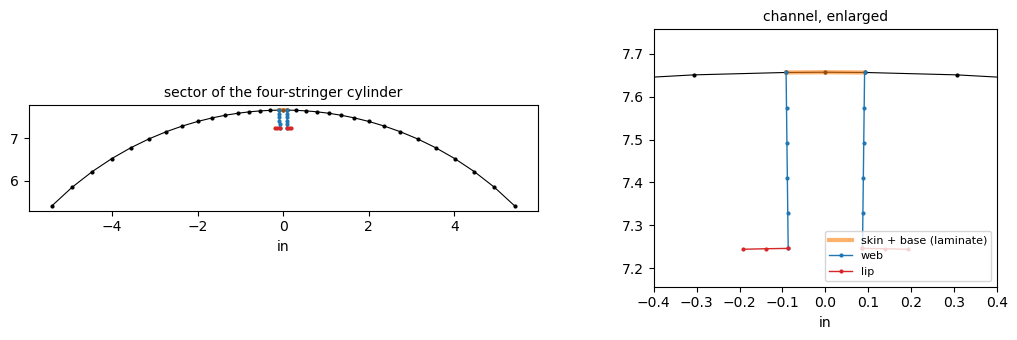

In [5]:
channel = dict(t=t, b=b, Hw=Hw, bl=bl, side='internal', base='laminate')
common = dict(R=R, L=L, h=h, E=E, nu=nu, rho=rho)


def plot_section_mesh(ax, model, zoom=False):
    R = model.R
    th = model.theta
    ax.plot(R*np.sin(th - model.phi/2), R*np.cos(th - model.phi/2), '.-',
            color='k', ms=4, lw=0.8)
    jw = model.j_webs
    ax.plot(R*np.sin(th[jw[0]:jw[1] + 1] - model.phi/2),
            R*np.cos(th[jw[0]:jw[1] + 1] - model.phi/2), 'C1-', lw=3,
            alpha=0.6, label='skin + base (laminate)')
    for s in range(2):
        tw = th[jw[s]] - model.phi/2
        r = R + model.Yweb
        ax.plot(r*np.sin(tw), r*np.cos(tw), 'C0.-', ms=4, lw=1,
                label='web' if s == 0 else None)
        rl = R + model.Yweb[-1]
        tl = tw + model.Ylip[s]/rl
        ax.plot(rl*np.sin(tl), rl*np.cos(tl), 'C3.-', ms=4, lw=1,
                label='lip' if s == 0 else None)
    ax.set_aspect('equal')
    if zoom:
        ax.set_xlim(-0.4, 0.4)
        ax.set_ylim(R - 0.5, R + 0.1)
    ax.set_xlabel('in')


demo = ChannelCylinderSector(nstringers=4, nx=5, nbay=15, ratio=3.,
                             channel=channel, nbase=2, nweb=5, nlip=2,
                             **common)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_section_mesh(axes[0], demo)
axes[0].set_title('sector of the four-stringer cylinder', fontsize=10)
plot_section_mesh(axes[1], demo, zoom=True)
axes[1].set_title('channel, enlarged', fontsize=10)
axes[1].legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

## Published values

- Table 3 of [1] (page 524): four stringers, columns a (symmetric modes),
  b (antisymmetric modes) and c (unstiffened), $m$ = 1 to 4, $n$ = 3 to 12;
  typed from the page and checked against the PDF text layer.
- Figures 3 and 4 of [1] (page 523): four and eight stringers, theory
  (Figure 3: symmetric, solid, and antisymmetric, dashed; Figure 4:
  symmetric only) and the tests of Ref. 8 of [1].
- Figure 12 of [2] (report page 52): eight stringers, simply supported,
  tests of Ref. 15 of [2] (the same tests) and the two smeared analyses.

The curves were read at integer $n$ and the test symbols at their centres
from 300 dpi images of the scanned pages, with the axes calibrated on the
tick marks. Reading precision (stated in the header of each file, with
notes per value): Figures 3 and 4 of [1], about 1 Hz per pixel, curves
$\pm$2 to 3 Hz, test symbols $\pm$1.5 Hz ($\pm$3 Hz where symbols overlap);
Figure 12 of [2], 0.45 Hz per pixel, curves $\pm$2 Hz where flat (more on
the steep parts), test symbols $\pm$1 Hz. Where the theory of Figure 3 of
[1] is hidden by a test symbol at integer $n$ it was not read (Table 3 gives
it). The same tests read from Figure 12 of [2] and from Figure 4 of [1]
differ by 1.7 Hz on average (largest 5.9 Hz).

In [6]:
def read_csv(path):
    with open(path, encoding='utf-8') as f:
        lines = [line for line in f if not line.startswith('#')]
    return list(csv.DictReader(lines))


table3 = {}                                  # (m, n, family) -> Hz
theory = {'fig3': {}, 'fig4': {}}            # (m, n, family) -> Hz
tests = {'fig3': [], 'fig4': [], 'fig12': []}  # (m, n, Hz)
for r in read_csv('results/egle1968_few_stringers.csv'):
    key = (int(r['m']), int(r['n']))
    f = float(r['f_Hz'])
    if r['source'] == 'table3':
        table3[key + (r['symmetry'],)] = f
    elif r['kind'] == 'theory':
        theory[r['source']][key + (r['symmetry'],)] = f
    else:
        tests[r['source']].append(key + (f,))
fig12 = {'present': {}, 'ref13': {}}         # (m, n) -> Hz
for r in read_csv('results/sewall1968_fig12_eight_stringers.csv'):
    key = (int(r['m']), int(r['n']))
    if r['kind'] == 'test':
        tests['fig12'].append(key + (float(r['f_Hz']),))
    else:
        fig12[r['kind']][key] = float(r['f_Hz'])
print('Table 3 of [1]:', len(table3), 'values')
print('Figure 3 of [1]: theory', len(theory['fig3']), ', tests',
      len(tests['fig3']))
print('Figure 4 of [1]: theory', len(theory['fig4']), ', tests',
      len(tests['fig4']))
print('Figure 12 of [2]: present', len(fig12['present']), ', Ref. 13',
      len(fig12['ref13']), ', tests', len(tests['fig12']))

Table 3 of [1]: 120 values
Figure 3 of [1]: theory 33 , tests 27
Figure 4 of [1]: theory 36 , tests 25
Figure 12 of [2]: present 37 , Ref. 13 37 , tests 24


## Analyses and mesh convergence

Three cylinders: four stringers, eight stringers and no stringers. The
unstiffened cylinder is modelled by a sector of $6°$ with the harmonic
$n = j$ directly ($n_s = 60$ without stringers, no coupling for $n < 30$).
Each analysis computes all the modes up to 10 % above the largest published
frequency it is compared with. Four meshes per cylinder,
`(nx, nbay, nweb, nlip)` (`(nx, nbay)` for the unstiffened sector), and on
the finest mesh three variants:

- FE\*, *without the in-surface inertia of the skin*: the mass of $u$, $v$
  and their derivatives of the skin removed (the plates keep theirs), the
  simplification of the analysis of [1] (page 522), which "for low values of
  $n$ should be expected to be somewhat higher than the correct values";
- FE\*D, *the assumptions of [1]*: as FE\*, with the skin element of
  Donnell-type kinematics, `BFSCCylinder`, as the strain-displacement
  relations of [1], Eq. (1) (page 519), instead of the Sanders-type element
  (in the ties of the webs the rotation of the skin is then $-w_{,y}$);
- *without the base*: the skin under the base is the skin alone, to show
  how much the base adds.

The analyses run in parallel processes.

In [7]:
mesh4 = [(21, 6, 2, 1), (31, 9, 3, 1), (41, 12, 4, 2), (51, 15, 5, 2)]
mesh8 = [(21, 4, 2, 1), (31, 6, 3, 1), (41, 8, 4, 2), (51, 10, 5, 2)]
meshU = [(21, 1), (31, 2), (41, 3), (51, 4)]

fmax = {4: 1.1*max(list(table3.values())
                   + list(theory['fig3'].values())
                   + [f for _, _, f in tests['fig3']]),
        8: 1.1*max(list(theory['fig4'].values())
                   + list(fig12['present'].values())
                   + list(fig12['ref13'].values())
                   + [f for _, _, f in tests['fig4'] + tests['fig12']])}
fmax[0] = 1.1*max(f for (m, n, fam), f in table3.items() if fam == 'none')
print('fmax (Hz):', {k: round(v) for k, v in fmax.items()})


def case(ns, mesh, variant='', keep_modes=False):
    c = dict(common, nx=mesh[0], nbay=mesh[1], keep_modes=keep_modes,
             skin_inplane_inertia=(variant == '' or variant == 'no base'),
             kinematics='donnell' if variant == 'Donnell' else 'sanders')
    if ns == 0:
        c.update(nstringers=60, fmax=fmax[0], js=range(1, 14))
    else:
        ch = dict(channel, base='none' if variant == 'no base' else
                  'laminate')
        c.update(nstringers=ns, ratio=3., channel=ch, nbase=2,
                 nweb=mesh[2], nlip=mesh[3], fmax=fmax[ns])
    return c


jobs = {}
for ns, meshes in [(4, mesh4), (8, mesh8), (0, meshU)]:
    for mesh in meshes:
        jobs[(ns, mesh, '')] = case(ns, mesh, keep_modes=(mesh == meshes[-1]))
    for variant in ['no in-surface inertia', 'Donnell', 'no base']:
        if ns == 0 and variant == 'no base':
            continue
        jobs[(ns, meshes[-1], variant)] = case(ns, meshes[-1], variant)
# largest analyses first
keys = sorted(jobs, key=lambda k: -k[1][0]*k[1][1]*(2 if k[0] == 4 else 1))
t0 = time.time()
with Pool(min(8, os.cpu_count())) as pool:
    out = pool.map(solve_case, [jobs[k] for k in keys], chunksize=1)
runs = {k: dict(spec=o[1], dofs=o[2], time=o[3]) for k, o in zip(keys, out)}
print('%.0f s elapsed' % (time.time() - t0))

fmax (Hz): {4: 1843, 8: 866, 0: 1843}


287 s elapsed


The compared frequencies are, for four stringers, the 80 values of the
families a and b of Table 3 of [1]; for eight stringers, both families of
every $(m, n)$ of Figures 4 of [1] and 12 of [2], $n \le 12$; for the
unstiffened cylinder, the 40 values of column c of Table 3. For each mesh:
the number of complex degrees of freedom of the reduced sector ($j = 0$),
the run time, and the largest change of the compared frequencies from the
previous mesh.

In [8]:
def ftable(spec, ns):
    """(m, n, family) -> frequency of the lowest mode of that name"""
    return {k: d['f'] for k, d in table(spec, max(ns, 60) if ns == 0
                                         else ns).items()}


compared = {
    4: sorted(k for k in table3 if k[2] in ('sym', 'antisym')),
    8: sorted({(m, n, fam) for (m, n) in
               {k[:2] for k in theory['fig4']}
               | {k[:2] for k in fig12['present']}
               | {k[:2] for k in fig12['ref13']}
               | {(m, n) for m, n, _ in tests['fig4'] + tests['fig12']}
               for fam in ('sym', 'antisym') if n <= 12}),
    0: sorted((m, n, 'sym') for (m, n, fam) in table3 if fam == 'none'),
}
final = {4: mesh4[-1], 8: mesh8[-1], 0: meshU[-1]}
names = {4: 'four stringers', 8: 'eight stringers', 0: 'unstiffened'}
for ns, meshes in [(4, mesh4), (8, mesh8), (0, meshU)]:
    print('\n%s, %d compared frequencies' % (names[ns], len(compared[ns])))
    print('mesh                 dofs   time (s)  missing  largest change')
    prev = None
    for mesh in meshes:
        r = runs[(ns, mesh, '')]
        f = ftable(r['spec'], ns)
        vals = np.array([f.get(k, np.nan) for k in compared[ns]])
        change = ''
        if prev is not None:
            d = np.abs(vals/prev - 1)
            i = np.nanargmax(d)
            change = '%.2f %% at (m, n) = %s' % (100*d[i],
                                                 compared[ns][i][:2])
        print('%-18s %7d %9.0f %8d   %s' % (mesh, r['dofs'], r['time'],
                                           np.isnan(vals).sum(), change))
        prev = vals


four stringers, 80 compared frequencies
mesh                 dofs   time (s)  missing  largest change
(21, 6, 2, 1)         4200        24        0   
(31, 9, 3, 1)         8696        70        0   4.91 % at (m, n) = (3, 3)
(41, 12, 4, 2)       15596       151        0   1.56 % at (m, n) = (4, 6)
(51, 15, 5, 2)       23492       287        0   0.36 % at (m, n) = (4, 10)

eight stringers, 76 compared frequencies
mesh                 dofs   time (s)  missing  largest change
(21, 4, 2, 1)         3392         6        0   
(31, 6, 3, 1)         6884        22        0   2.31 % at (m, n) = (4, 12)
(41, 8, 4, 2)        12380        61        0   0.64 % at (m, n) = (3, 8)
(51, 10, 5, 2)       18472       120        0   0.27 % at (m, n) = (3, 8)

unstiffened, 40 compared frequencies
mesh                 dofs   time (s)  missing  largest change
(21, 1)                404         1        0   
(31, 2)               1208         2        0   1.80 % at (m, n) = (4, 9)
(41, 3)               2412

The finest meshes are used below: from the previous mesh, every compared
frequency changes by less than 1 % (last line of each cylinder).

## Four stringers against Table 3 of [1]

The relative difference is (FE - reference)/reference. FE is the model,
FE\* the model without the in-surface inertia of the skin, FE\*D the
same with Donnell-type kinematics (the assumptions of [1]). For
odd $n$ the symmetric and antisymmetric frequencies are equal, in [1] and
in the model (a pair of modes of a complex Bloch index).

In [9]:
res = {k: ftable(r['spec'], k[0]) for k, r in runs.items()
       if k[1] == final[k[0]]}
fe4, fe4s = res[(4, final[4], '')], res[(4, final[4], 'no in-surface inertia')]
fe4b = res[(4, final[4], 'no base')]
fe4d = res[(4, final[4], 'Donnell')]
fe8, fe8s = res[(8, final[8], '')], res[(8, final[8], 'no in-surface inertia')]
fe8b = res[(8, final[8], 'no base')]
fe8d = res[(8, final[8], 'Donnell')]
feU, feUs = res[(0, final[0], '')], res[(0, final[0], 'no in-surface inertia')]
feUd = res[(0, final[0], 'Donnell')]

summary = []


def rel(a, b):
    return a/b - 1


for fam, col in [('sym', 'a'), ('antisym', 'b')]:
    print('\n%s modes, Table 3 column %s' % (fam, col))
    print(' m   n |  Table 3 %s |      FE   diff |     FE*   diff |    FE*D   diff'
          % col)
    d, ds, dd = [], [], []
    for m in range(1, 5):
        for n in range(3, 13):
            ref = table3[(m, n, fam)]
            vals = [fe.get((m, n, fam), np.nan) for fe in (fe4, fe4s, fe4d)]
            for x, f in zip((d, ds, dd), vals):
                x.append(rel(f, ref))
            print('%2d %3d | %10.1f |' % (m, n, ref) + ''.join(
                ' %7.1f %+5.1f%% |' % (f, 100*rel(f, ref)) for f in vals))
    summary += [('4 stringers, FE vs Table 3 %s (%s)' % (col, fam), d),
                ('4 stringers, FE* vs Table 3 %s (%s)' % (col, fam), ds),
                ('4 stringers, FE*D vs Table 3 %s (%s)' % (col, fam), dd)]


sym modes, Table 3 column a
 m   n |  Table 3 a |      FE   diff |     FE*   diff |    FE*D   diff
 1   3 |      169.0 |   160.2  -5.2% |   168.4  -0.3% |   169.0  +0.0% |
 1   4 |      103.0 |    99.3  -3.6% |   102.0  -0.9% |   103.3  +0.3% |
 1   5 |       94.7 |    91.5  -3.4% |    93.2  -1.6% |    95.4  +0.7% |
 1   6 |      109.0 |   107.1  -1.7% |   108.4  -0.5% |   111.0  +1.8% |
 1   7 |      145.0 |   141.0  -2.8% |   142.6  -1.6% |   145.3  +0.2% |
 1   8 |      183.0 |   181.5  -0.8% |   183.0  -0.0% |   185.8  +1.5% |
 1   9 |      236.0 |   232.8  -1.3% |   234.3  -0.7% |   237.2  +0.5% |
 1  10 |      278.0 |   276.7  -0.5% |   280.0  +0.7% |   282.6  +1.7% |
 1  11 |      350.0 |   348.3  -0.5% |   349.8  -0.0% |   352.7  +0.8% |
 1  12 |      408.0 |   410.4  +0.6% |   411.9  +1.0% |   414.8  +1.7% |
 2   3 |      591.0 |   556.4  -5.9% |   584.8  -1.1% |   585.0  -1.0% |
 2   4 |      346.0 |   336.1  -2.9% |   345.2  -0.2% |   345.9  -0.0% |
 2   5 |      241.0 |   

The splitting of the even $n$ into two frequencies, (sym - antisym)/antisym,
in [1] and in the model:

In [10]:
print(' m |' + ''.join('   n = %-2d       ' % n for n in range(4, 13, 2)))
print('   |' + '  [1]    FE     '*5)
for m in range(1, 5):
    row = '%2d |' % m
    for n in range(4, 13, 2):
        s1 = table3[(m, n, 'sym')]/table3[(m, n, 'antisym')] - 1
        s2 = fe4[(m, n, 'sym')]/fe4[(m, n, 'antisym')] - 1
        row += ' %+5.1f%% %+5.1f%%  ' % (100*s1, 100*s2)
    print(row)

 m |   n = 4           n = 6           n = 8           n = 10          n = 12       
   |  [1]    FE       [1]    FE       [1]    FE       [1]    FE       [1]    FE     
 1 |  -4.6%  -3.8%    -6.0%  -4.4%    -4.7%  -3.1%    -6.4%  -4.8%    -4.0%  -1.9%  
 2 |  -5.2%  -4.1%    -4.0%  -3.2%    -3.7%  -2.2%    -2.9%  -1.6%    -1.4%  -0.1%  
 3 |  -6.1%  -4.5%    -2.1%  -1.8%    +2.4%  +2.5%    +2.1%  +2.7%    -0.2%  +0.9%  
 4 |  -4.8%  -3.1%    -1.8%  -2.1%    +4.1%  +3.9%    +8.9%  +8.4%    +8.7%  +8.0%  


## Unstiffened cylinder against Table 3 of [1], column c

In [11]:
print(' m   n |  Table 3 c |      FE   diff |     FE*   diff |    FE*D   diff')
d, ds, dd = [], [], []
for m in range(1, 5):
    for n in range(3, 13):
        ref = table3[(m, n, 'none')]
        vals = [fe[(m, n, 'sym')] for fe in (feU, feUs, feUd)]
        for x, f in zip((d, ds, dd), vals):
            x.append(rel(f, ref))
        print('%2d %3d | %10.1f |' % (m, n, ref) + ''.join(
            ' %7.1f %+5.1f%% |' % (f, 100*rel(f, ref)) for f in vals))
summary += [('unstiffened, FE vs Table 3 c', d),
            ('unstiffened, FE* vs Table 3 c', ds),
            ('unstiffened, FE*D vs Table 3 c', dd)]

 m   n |  Table 3 c |      FE   diff |     FE*   diff |    FE*D   diff
 1   3 |      171.0 |   161.6  -5.5% |   170.8  -0.1% |   171.3  +0.2% |
 1   4 |      108.0 |   104.0  -3.7% |   107.3  -0.6% |   108.7  +0.6% |
 1   5 |       98.1 |    94.2  -3.9% |    96.2  -2.0% |    98.5  +0.4% |
 1   6 |      117.0 |   112.8  -3.6% |   114.4  -2.2% |   117.2  +0.2% |
 1   7 |      151.0 |   146.5  -3.0% |   148.0  -2.0% |   150.9  -0.0% |
 1   8 |      194.0 |   189.3  -2.4% |   190.7  -1.7% |   193.7  -0.1% |
 1   9 |      243.0 |   239.1  -1.6% |   240.6  -1.0% |   243.6  +0.2% |
 1  10 |      300.0 |   295.4  -1.5% |   296.8  -1.1% |   299.8  -0.1% |
 1  11 |      362.0 |   357.8  -1.2% |   359.2  -0.8% |   362.2  +0.1% |
 1  12 |      431.0 |   426.2  -1.1% |   427.7  -0.8% |   430.7  -0.1% |
 2   3 |      602.0 |   568.2  -5.6% |   602.4  +0.1% |   602.6  +0.1% |
 2   4 |      365.0 |   353.2  -3.2% |   365.1  +0.0% |   365.5  +0.1% |
 2   5 |      251.0 |   246.0  -2.0% |   251.2  +0.1%

## Four stringers against the tests and the curves of Figure 3 of [1]

A test does not say whether the resonance belongs to the symmetric or to
the antisymmetric family: it is compared with the nearer of the two FE
frequencies (both shown), and so is the theory of [1] (Table 3 a and b).

In [12]:
def nearest(fe, m, n):
    fs = [fe[(m, n, fam)] for fam in ('sym', 'antisym') if (m, n, fam) in fe]
    return fs


print(' m   n |   test |  FE sym  FE anti   diff | Table 3 a    b    diff')
d, dt = [], []
for m, n, ftest in sorted(tests['fig3']):
    fs = nearest(fe4, m, n)
    f = min(fs, key=lambda x: abs(x - ftest))
    d.append(rel(f, ftest))
    row = '%2d %3d | %6.1f | %7.1f %7.1f  %+5.1f%% |' % (
        m, n, ftest, fe4[(m, n, 'sym')], fe4[(m, n, 'antisym')],
        100*rel(f, ftest))
    if (m, n, 'sym') in table3:
        a, bb = table3[(m, n, 'sym')], table3[(m, n, 'antisym')]
        g = min([a, bb], key=lambda x: abs(x - ftest))
        dt.append(rel(g, ftest))
        row += ' %8.1f %6.1f  %+5.1f%%' % (a, bb, 100*rel(g, ftest))
    print(row)
summary += [('4 stringers, FE vs tests (Fig. 3)', d),
            ('4 stringers, [1] Table 3 vs tests (Fig. 3)', dt)]

print('\nTheory curves of Figure 3, where readable (Table 3 has them all):')
print(' m   n  family   Fig. 3     FE    diff')
d = []
for (m, n, fam), ref in sorted(theory['fig3'].items()):
    f = fe4[(m, n, fam)]
    d.append(rel(f, ref))
    print('%2d %3d  %-7s  %6.1f  %6.1f  %+5.1f%%' % (m, n, fam, ref, f,
                                                     100*rel(f, ref)))
summary.append(('4 stringers, FE vs Fig. 3 theory (digitised)', d))

 m   n |   test |  FE sym  FE anti   diff | Table 3 a    b    diff
 1   4 |  104.1 |    99.3   103.2   -0.8% |    103.0  108.0   -1.1%
 1   5 |   91.4 |    91.5    91.5   +0.1% |     94.7   94.7   +3.6%
 1   6 |  105.6 |   107.1   112.0   +1.4% |    109.0  116.0   +3.2%
 1   7 |  139.8 |   141.0   141.0   +0.8% |    145.0  145.0   +3.7%
 1   8 |  178.0 |   181.5   187.4   +2.0% |    183.0  192.0   +2.8%
 1   9 |  228.2 |   232.8   232.8   +2.0% |    236.0  236.0   +3.4%
 1  10 |  268.3 |   276.7   290.7   +3.1% |    278.0  297.0   +3.6%
 1  12 |  401.5 |   410.4   418.4   +2.2% |    408.0  425.0   +1.6%
 2   4 |  338.3 |   336.1   350.5   -0.6% |    346.0  365.0   +2.3%
 2   5 |  230.9 |   236.5   236.5   +2.4% |    241.0  241.0   +4.4%
 2   6 |  197.4 |   191.3   197.7   +0.1% |    194.0  202.0   -1.7%
 2   7 |  191.7 |   189.0   189.0   -1.4% |    191.0  191.0   -0.4%
 2   8 |  209.9 |   208.1   212.7   -0.9% |    209.0  217.0   -0.4%
 2   9 |  242.1 |   253.1   253.1   +4.6% |    25

## Eight stringers against Figure 4 of [1] and Figure 12 of [2]

The theory of Figure 4 of [1] is drawn for the symmetric modes only. The
tests of Figure 4 of [1] and Figure 12 of [2] are the same tests, read
twice. The smeared analyses of [2] have no symmetric and antisymmetric
families: they are compared with the mean of the two FE frequencies (equal
except for $n$ = 4, 8, 12).

In [13]:
print('Theory of Figure 4 of [1], symmetric modes')
print(' m   n |  Fig. 4 |      FE   diff |     FE*   diff |    FE*D   diff')
d, ds, dd = [], [], []
for (m, n, fam), ref in sorted(theory['fig4'].items()):
    vals = [fe[(m, n, 'sym')] for fe in (fe8, fe8s, fe8d)]
    for x, f in zip((d, ds, dd), vals):
        x.append(rel(f, ref))
    print('%2d %3d | %7.1f |' % (m, n, ref) + ''.join(
        ' %7.1f %+5.1f%% |' % (f, 100*rel(f, ref)) for f in vals))
print('FE, symmetric modes (1, 12): %.1f Hz, (2, 12): %.1f Hz'
      % (fe8[(1, 12, 'sym')], fe8[(2, 12, 'sym')]))
summary += [('8 stringers, FE vs Fig. 4 theory (sym)', d),
            ('8 stringers, FE* vs Fig. 4 theory (sym)', ds),
            ('8 stringers, FE*D vs Fig. 4 theory (sym)', dd)]

for src, label in [('fig4', 'Figure 4 of [1]'), ('fig12', 'Figure 12 of [2]')]:
    print('\nTests of %s' % label)
    print(' m   n |   test |  FE sym  FE anti   diff')
    d = []
    for m, n, ftest in sorted(tests[src]):
        fs = nearest(fe8, m, n)
        f = min(fs, key=lambda x: abs(x - ftest))
        d.append(rel(f, ftest))
        print('%2d %3d | %6.1f | %7.1f %7.1f  %+5.1f%%'
              % (m, n, ftest, fe8[(m, n, 'sym')], fe8[(m, n, 'antisym')],
                 100*rel(f, ftest)))
    summary.append(('8 stringers, FE vs tests (%s)' % label.split(' of')[0]
                    .replace('Figure', 'Fig.'), d))

print('\nSmeared analyses of Figure 12 of [2]')
print(' m   n | FE mean | present   diff | Ref. 13   diff')
dp, dr = [], []
for m in range(1, 5):
    for n in range(2, 13):
        if (m, n) not in fig12['present'] and (m, n) not in fig12['ref13']:
            continue
        f = 0.5*(fe8[(m, n, 'sym')] + fe8[(m, n, 'antisym')])
        row = '%2d %3d | %7.1f |' % (m, n, f)
        for key, dd in [('present', dp), ('ref13', dr)]:
            ref = fig12[key].get((m, n))
            if ref is None:
                row += '                |'
                continue
            dd.append(rel(f, ref))
            row += ' %7.1f %+5.1f%% |' % (ref, 100*rel(f, ref))
        print(row)
summary += [('8 stringers, FE vs Fig. 12 present (smeared)', dp),
            ('8 stringers, FE vs Fig. 12 Ref. 13 (equiv. shell)', dr)]

Theory of Figure 4 of [1], symmetric modes
 m   n |  Fig. 4 |      FE   diff |     FE*   diff |    FE*D   diff
 1   2 |   351.6 |   323.4  -8.0% |   356.5  +1.4% |   356.7  +1.5% |
 1   3 |   161.5 |   156.1  -3.3% |   163.9  +1.5% |   164.3  +1.7% |
 1   4 |   101.4 |    96.1  -5.2% |    98.4  -2.9% |    99.6  -1.8% |
 1   5 |    93.5 |    89.0  -4.8% |    90.6  -3.1% |    92.7  -0.8% |
 1   6 |   108.3 |   106.4  -1.7% |   107.7  -0.5% |   110.3  +1.8% |
 1   7 |   140.6 |   137.9  -1.9% |   139.1  -1.1% |   141.8  +0.9% |
 1   8 |   171.4 |   171.8  +0.2% |   172.8  +0.8% |   175.5  +2.4% |
 1   9 |   227.9 |   225.7  -1.0% |   227.0  -0.4% |   229.7  +0.8% |
 1  10 |   275.5 |   270.4  -1.9% |   274.1  -0.5% |   276.5  +0.4% |
 1  11 |   347.5 |   340.3  -2.1% |   342.1  -1.6% |   344.8  -0.8% |
 2   3 |   578.9 |   556.4  -3.9% |   584.3  +0.9% |   584.2  +0.9% |
 2   4 |   316.6 |   311.5  -1.6% |   317.7  +0.3% |   318.4  +0.6% |
 2   5 |   234.8 |   232.4  -1.0% |   236.6  +0.8

## Summary of the relative differences

In [14]:
print('%-52s %5s %8s %8s %8s' % ('comparison', 'count', 'mean', 'min', 'max'))
for label, d in summary:
    d = 100*np.array(d)
    print('%-52s %5d %+7.1f%% %+7.1f%% %+7.1f%%' % (label, len(d), np.nanmean(d),
                                                    np.nanmin(d), np.nanmax(d)))

comparison                                           count     mean      min      max
4 stringers, FE vs Table 3 a (sym)                      40    -1.5%    -5.9%    +0.6%
4 stringers, FE* vs Table 3 a (sym)                     40    -0.1%    -1.6%    +1.0%
4 stringers, FE*D vs Table 3 a (sym)                    40    +0.6%    -1.0%    +1.8%
4 stringers, FE vs Table 3 b (antisym)                  40    -2.0%    -5.9%    -0.3%
4 stringers, FE* vs Table 3 b (antisym)                 40    -0.6%    -2.6%    +0.8%
4 stringers, FE*D vs Table 3 b (antisym)                40    +0.1%    -2.6%    +1.0%
unstiffened, FE vs Table 3 c                            40    -2.1%    -5.6%    -0.6%
unstiffened, FE* vs Table 3 c                           40    -0.5%    -2.2%    +0.1%
unstiffened, FE*D vs Table 3 c                          40    +0.2%    -0.1%    +0.6%
4 stringers, FE vs tests (Fig. 3)                       27    +1.4%    -1.4%    +4.8%
4 stringers, [1] Table 3 vs tests (Fig. 3)            

## Frequencies against $n$

Lines: the model (solid symmetric, dashed antisymmetric; for odd $n$ with
four stringers, and $n$ not a multiple of 4 with eight, both are the same
pair). Four stringers: Table 3 of [1] (filled: a, open: b) and the tests of
Figure 3 of [1] (black). Eight stringers: the symmetric theory of Figure 4
of [1] (crosses), the smeared analyses of Figure 12 of [2] (dotted:
"Present paper", dash-dot: Ref. 13) and the tests of Figures 4 of [1]
(black) and 12 of [2] (grey).

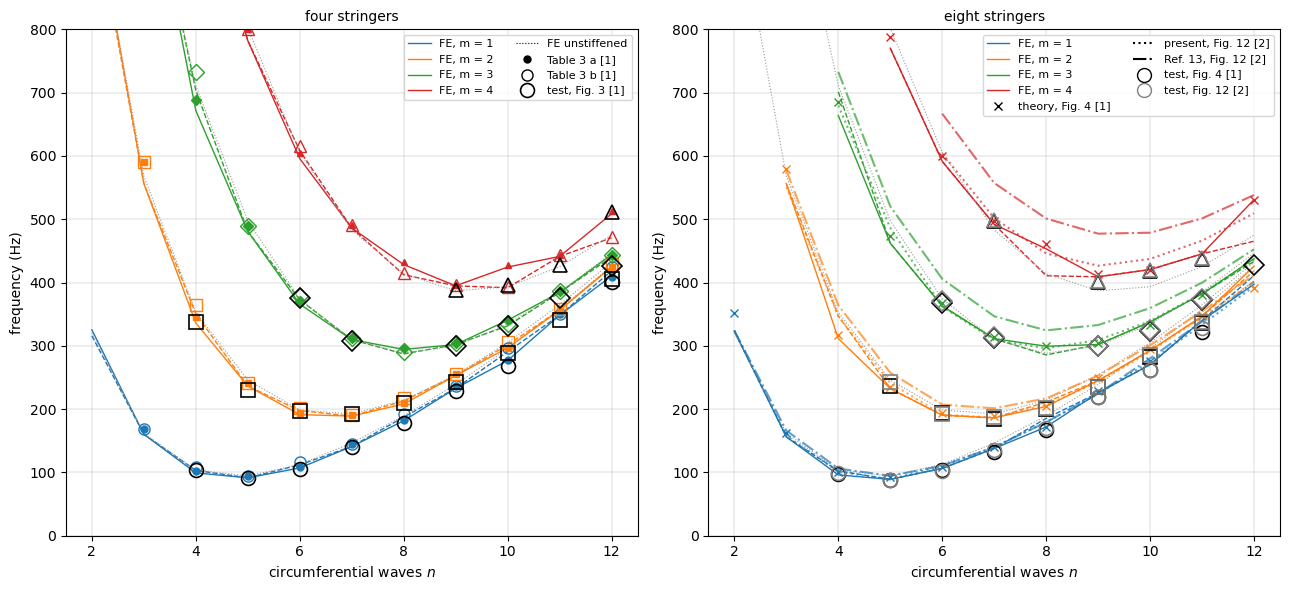

In [15]:
marker = {1: 'o', 2: 's', 3: 'D', 4: '^'}
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
ns = np.arange(2, 13)
for ax, fe, ns_ in [(axes[0], fe4, 4), (axes[1], fe8, 8)]:
    for m in range(1, 5):
        c = 'C%d' % (m - 1)
        for fam, ls in [('sym', '-'), ('antisym', '--')]:
            x = [n for n in ns if (m, n, fam) in fe]
            ax.plot(x, [fe[(m, n, fam)] for n in x], ls, color=c, lw=1,
                    label='FE, m = %d' % m if fam == 'sym' else None)
        x = [n for n in ns if (m, n, 'sym') in feU]
        ax.plot(x, [feU[(m, n, 'sym')] for n in x], ':', color='0.6', lw=0.8)
for m in range(1, 5):
    c = 'C%d' % (m - 1)
    x = list(range(3, 13))
    axes[0].plot(x, [table3[(m, n, 'sym')] for n in x], marker[m], color=c,
                 ms=5)
    axes[0].plot(x, [table3[(m, n, 'antisym')] for n in x], marker[m],
                 color=c, mfc='none', ms=8)
    x = sorted(n for (mm, n, fam) in theory['fig4'] if mm == m)
    axes[1].plot(x, [theory['fig4'][(m, n, 'sym')] for n in x], 'x',
                 color=c, ms=6)
    for key, ls in [('present', ':'), ('ref13', '-.')]:
        x = sorted(n for (mm, n) in fig12[key] if mm == m)
        axes[1].plot(x, [fig12[key][(m, n)] for n in x], ls, color=c,
                     lw=1.5, alpha=0.7)
for ax, srcs in [(axes[0], [('fig3', 'k')]),
                 (axes[1], [('fig4', 'k'), ('fig12', '0.5')])]:
    for src, c in srcs:
        for m, n, f in tests[src]:
            ax.plot([n], [f], marker[m], color=c, mfc='none', ms=10, mew=1.2)
    ax.set_ylim(0, 800)
    ax.set_xlim(1.5, 12.5)
    ax.grid(True, lw=0.3)
    ax.set_xlabel('circumferential waves $n$')
    ax.set_ylabel('frequency (Hz)')
axes[0].plot([], [], 'k:', lw=0.8, label='FE unstiffened')
axes[0].plot([], [], 'ko', ms=5, label='Table 3 a [1]')
axes[0].plot([], [], 'ko', mfc='none', ms=8, label='Table 3 b [1]')
axes[0].plot([], [], 'ko', mfc='none', ms=10, mew=1.2, label='test, Fig. 3 [1]')
axes[1].plot([], [], 'kx', label='theory, Fig. 4 [1]')
axes[1].plot([], [], 'k:', lw=1.5, label='present, Fig. 12 [2]')
axes[1].plot([], [], 'k-.', lw=1.5, label='Ref. 13, Fig. 12 [2]')
axes[1].plot([], [], 'ko', mfc='none', ms=10, label='test, Fig. 4 [1]')
axes[1].plot([], [], 'o', color='0.5', mfc='none', ms=10,
             label='test, Fig. 12 [2]')
axes[0].set_title('four stringers', fontsize=10)
axes[1].set_title('eight stringers', fontsize=10)
axes[0].legend(fontsize=8, ncol=2, loc='upper right')
axes[1].legend(fontsize=8, ncol=2, loc='upper right')
plt.tight_layout()
plt.show()

## The in-surface inertia and the base

The ratios FE\*/FE and FE\*D/FE of the variants with the assumptions of [1]
to the model, and of the frequencies without the base to those with it, for
the symmetric modes; the dotted lines with symbols are column c of Table 3
of [1] over the unstiffened model.

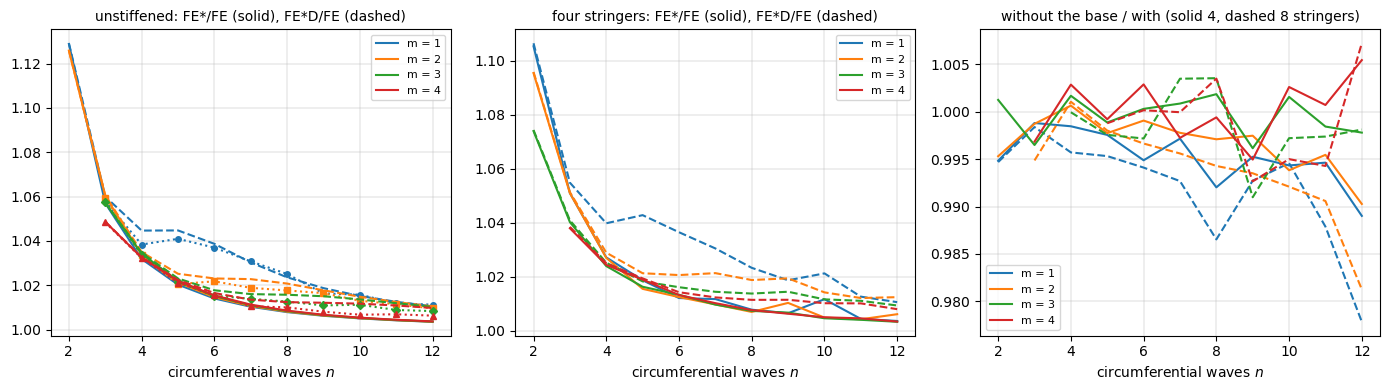

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)
ns = np.arange(2, 13)
for m in range(1, 5):
    c = 'C%d' % (m - 1)
    for ax, fe, fes, fed, lab in [(axes[0], feU, feUs, feUd, 'unstiffened'),
                                  (axes[1], fe4, fe4s, fe4d, 'four stringers')]:
        x = [n for n in ns if (m, n, 'sym') in fe and (m, n, 'sym') in fes]
        ax.plot(x, [fes[(m, n, 'sym')]/fe[(m, n, 'sym')] for n in x], '-',
                color=c, label='m = %d' % m)
        x = [n for n in ns if (m, n, 'sym') in fe and (m, n, 'sym') in fed]
        ax.plot(x, [fed[(m, n, 'sym')]/fe[(m, n, 'sym')] for n in x], '--',
                color=c)
        ax.set_title('%s: FE*/FE (solid), FE*D/FE (dashed)' % lab,
                     fontsize=10)
    x = [n for n in range(3, 13)]
    axes[0].plot(x, [table3[(m, n, 'none')]/feU[(m, n, 'sym')] for n in x],
                 ':', marker=marker[m], ms=4, color=c)
    for fe, feb, ls in [(fe4, fe4b, '-'), (fe8, fe8b, '--')]:
        x = [n for n in ns if (m, n, 'sym') in fe and (m, n, 'sym') in feb]
        axes[2].plot(x, [feb[(m, n, 'sym')]/fe[(m, n, 'sym')] for n in x], ls,
                     color=c, label='m = %d' % m if ls == '-' else None)
axes[2].set_title('without the base / with (solid 4, dashed 8 stringers)',
                  fontsize=10)
for ax in axes:
    ax.grid(True, lw=0.3)
    ax.set_xlabel('circumferential waves $n$')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Modal coupling and mode shapes

[1] (pages 524 and 525) gives, for the symmetric modes of its Figures 5 and
6, the frequency and the ratio of the second largest to the largest
coefficient of $w$: four stringers, $m = 1$, $n = 4$: 102.8 Hz, 0.0618;
$m = 1$, $n = 8$: 183.0 Hz, 0.194; $m = 2$, $n = 9$: 256.5 Hz, with "a
strong coupling effect of the fifth mode on the ninth", 0.720; $m = 2$, $n =
15$: 659.0 Hz; and the coupling of $n = 15$ on $m = 2$, $n = 3$, 0.247. Eight
stringers: $m = 1$, $n = 4$: 98.9 Hz, 0.0178; $m = 1$, $n = 8$: 170.3 Hz,
0.00228; $m = 1$, $n = 13$: 475.1 Hz; $m = 2$, $n = 13$: 475.7 Hz. The same
quantities of the model, with the $(m, n)$ of the second largest
coefficient:

In [17]:
spec = {4: runs[(4, final[4], '')]['spec'], 8: runs[(8, final[8], '')]['spec']}
tabs = {ns: table(spec[ns], ns) for ns in (4, 8)}
# (n_s, m, n, frequency of [1], ratio of [1], harmonic named by [1])
egle_modes = [(4, 1, 4, 102.8, 0.0618, None), (4, 1, 8, 183.0, 0.194, None),
              (4, 2, 9, 256.5, 0.720, 5), (4, 2, 15, 659.0, None, None),
              (4, 2, 3, None, 0.247, 15), (8, 1, 4, 98.9, 0.0178, None),
              (8, 1, 8, 170.3, 0.00228, None), (8, 1, 13, 475.1, None, None),
              (8, 2, 13, 475.7, None, None)]
print('ns  m   n |  f [1]    FE    diff | ratio [1]    FE   second (m, n)'
      ' | harmonic named by [1]')
for ns, m, n, f1, r1, n1 in egle_modes:
    d = tabs[ns].get((m, n, 'sym'))
    if d is None:
        print('%2d %2d %3d | no FE mode with this name' % (ns, m, n))
        continue
    amp = np.sqrt(d['a']**2 + d['b']**2)
    order = np.argsort(amp.ravel())[::-1]
    m2, n2 = np.unravel_index(order[1], amp.shape)
    fs = '%6.1f %6.1f %+5.1f%%' % (f1, d['f'], 100*rel(d['f'], f1)) if f1 \
        else '     - %6.1f      ' % d['f']
    rs = '%9.4f' % r1 if r1 else '        -'
    named = ''
    if n1 is not None:
        named = ' | n = %d: %.4f' % (n1, amp[m - 1, n1]/amp.max())
    print('%2d %2d %3d | %s | %s  %6.4f   (%d, %d)%s' % (
        ns, m, n, fs, rs, d['ratio'], m2 + 1, n2, named))

ns  m   n |  f [1]    FE    diff | ratio [1]    FE   second (m, n) | harmonic named by [1]
 4  1   4 |  102.8   99.3  -3.4% |    0.0618  0.0474   (1, 8)
 4  1   8 |  183.0  181.5  -0.8% |    0.1940  0.1707   (1, 4)
 4  2   9 |  256.5  253.1  -1.3% |    0.7200  0.5504   (2, 5) | n = 5: 0.5504
 4  2  15 |  659.0  657.4  -0.2% |         -  0.2353   (2, 3)
 4  2   3 |      -  556.4       |    0.2470  0.2188   (2, 13) | n = 15: 0.1858
 8  1   4 |   98.9   96.1  -2.8% |    0.0178  0.0101   (1, 12)
 8  1   8 |  170.3  171.8  +0.9% |    0.0023  0.0038   (1, 24)
 8  1  13 |  475.1  473.7  -0.3% |         -  0.1323   (1, 5)
 8  2  13 |  475.7  477.0  +0.3% |         -  0.2372   (2, 3)


The normal displacement $w$ along the circumference at mid-length,
normalised, for the modes of Figures 5 and 6 of [1] (the symmetric member of
each pair; the vertical lines are the stringers), to be compared with those
figures:

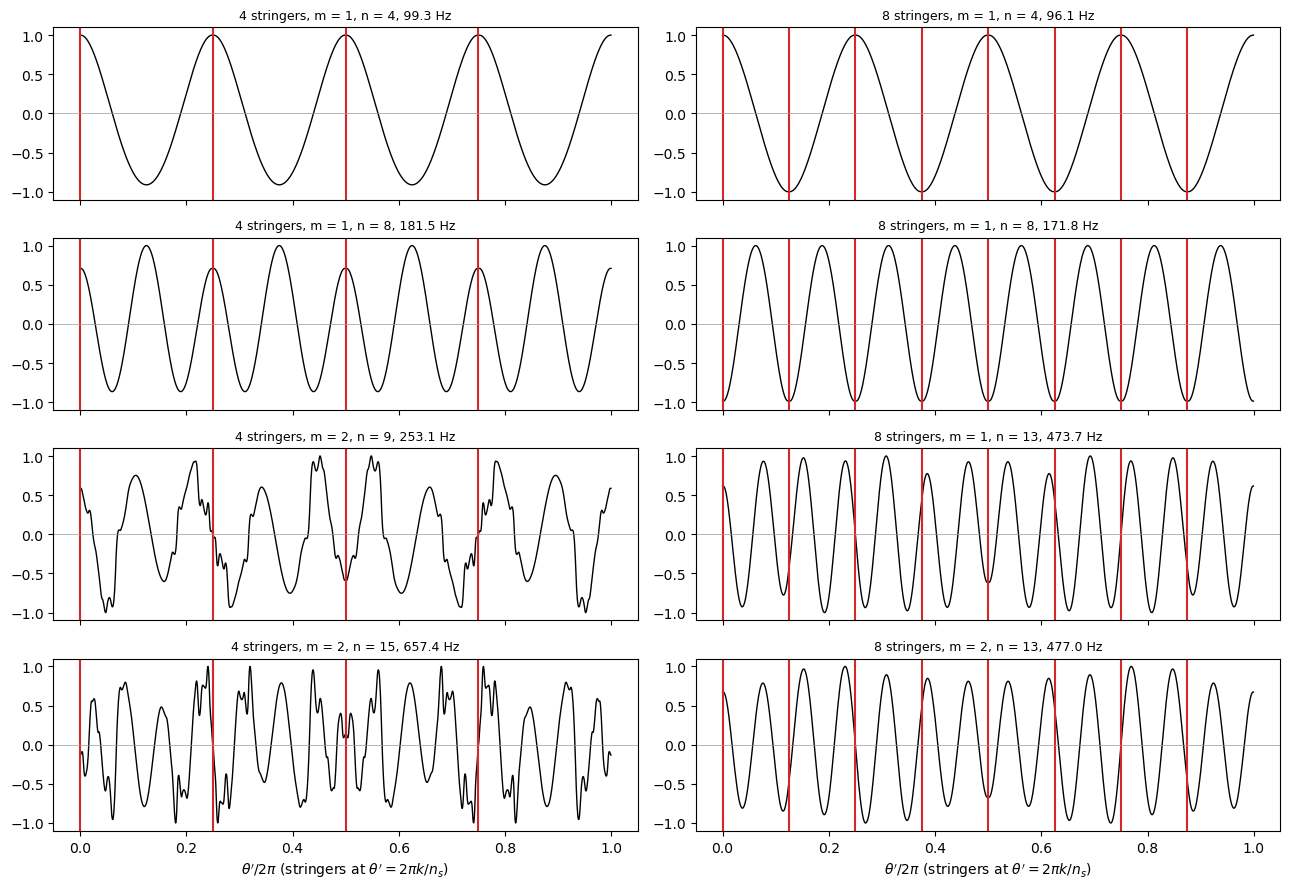

In [18]:
def models_for(ns):
    mesh = final[ns]
    return ChannelCylinderSector(nstringers=ns, nx=mesh[0], nbay=mesh[1],
                                 ratio=3., channel=channel, nbase=2,
                                 nweb=mesh[2], nlip=mesh[3], **common)


geo = {ns: models_for(ns) for ns in (4, 8)}


def symmetric_w(model, d, symmetric=True):
    """w(x, theta') of a mode; for a pair (complex Bloch index), of its
    symmetric (or antisymmetric) member, w(theta') +- w(-theta')"""
    thetap, w = model.full_w(d['mode'], d['j'], real=False)
    if 0 < d['j'] < model.nstringers/2:
        sign = 1 if symmetric else -1
        w = w + sign*np.roll(w[:, ::-1], 1, axis=1)
    return thetap, np.real(normalize_phase(w))


fig, axes = plt.subplots(4, 2, figsize=(13, 9), sharex=True)
for col, ns in enumerate([4, 8]):
    sel = [(m, n) for nss, m, n, f1, r1, n1 in egle_modes if nss == ns
           and (m, n) != (2, 3)]
    for row, (m, n) in enumerate(sel):
        d = tabs[ns][(m, n, 'sym')]
        model = geo[ns]
        thetap, w = symmetric_w(model, d)
        i = model.nx//2
        wi = w[i]/np.abs(w[i]).max()
        ax = axes[row, col]
        ax.plot(thetap/(2*np.pi), wi, 'k', lw=1)
        for k in range(ns):
            ax.axvline(k/ns, color='C3', lw=1.5)
        ax.axhline(0, color='0.6', lw=0.5)
        ax.set_ylim(-1.1, 1.1)
        ax.set_title('%d stringers, m = %d, n = %d, %.1f Hz'
                     % (ns, m, n, d['f']), fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel(r"$\theta'/2\pi$ (stringers at $\theta' = 2\pi k/n_s$)")
plt.tight_layout()
plt.show()

The normal displacement of the skin over the developed cylinder (from
$x = 0$ at the bottom to $x = L$ at the top) for the symmetric and the
antisymmetric mode of $m = 1$, $n = 4$ and of $m = 2$, $n = 6$ with four
stringers, and the lowest mode with eight stringers; the stringers are the
vertical lines:

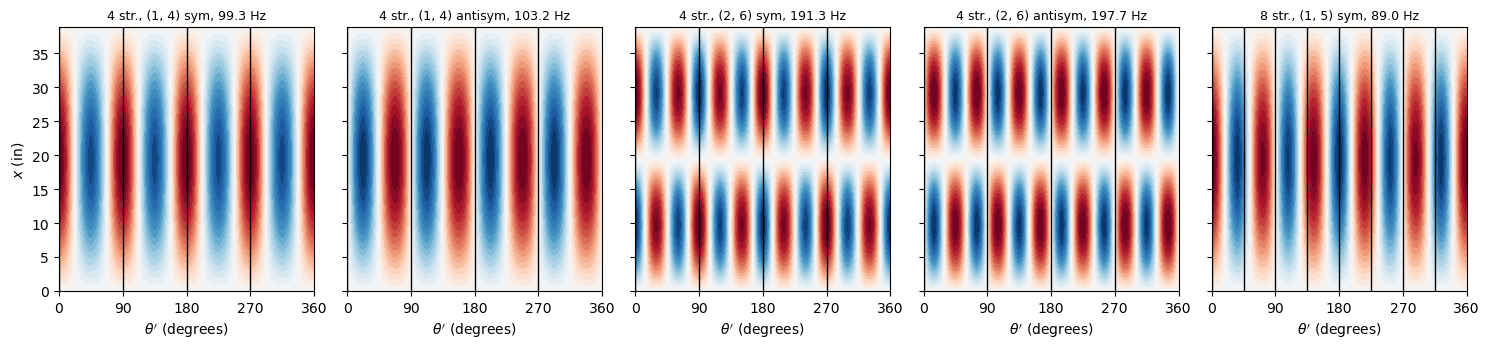

In [19]:
def plot_w(ax, model, d, title, symmetric=True):
    thetap, w = symmetric_w(model, d, symmetric)
    lim = np.abs(w).max()
    ax.contourf(np.degrees(thetap), model.xlin, w,
                levels=np.linspace(-lim, lim, 31), cmap='RdBu_r')
    for k in range(model.nstringers):
        ax.axvline(360*k/model.nstringers, color='k', lw=1)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([0, 90, 180, 270, 360])


f8 = min(spec[8], key=lambda d: d['f'])
panels = [(4, tabs[4][(1, 4, 'sym')], 'sym'), (4, tabs[4][(1, 4, 'antisym')],
                                               'antisym'),
          (4, tabs[4][(2, 6, 'sym')], 'sym'), (4, tabs[4][(2, 6, 'antisym')],
                                               'antisym'),
          (8, f8, 'sym')]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), sharey=True)
for ax, (ns, d, fam) in zip(axes, panels):
    plot_w(ax, geo[ns], d, '%d str., (%d, %d) %s, %.1f Hz'
           % (ns, d['m'], d['n'], fam, d['f']), fam == 'sym')
    ax.set_xlabel(r"$\theta'$ (degrees)")
axes[0].set_ylabel('$x$ (in)')
plt.tight_layout()
plt.show()

The cross-section at mid-length of the symmetric and antisymmetric modes
$m = 1$, $n = 4$ with four stringers, skin (black) and channels (red), the
displacements magnified. In the symmetric mode the stringers are at the
antinodes and move radially (bending), in the antisymmetric mode at the
nodes and rotate (torsion), as [1] explains (pages 523 and 524):

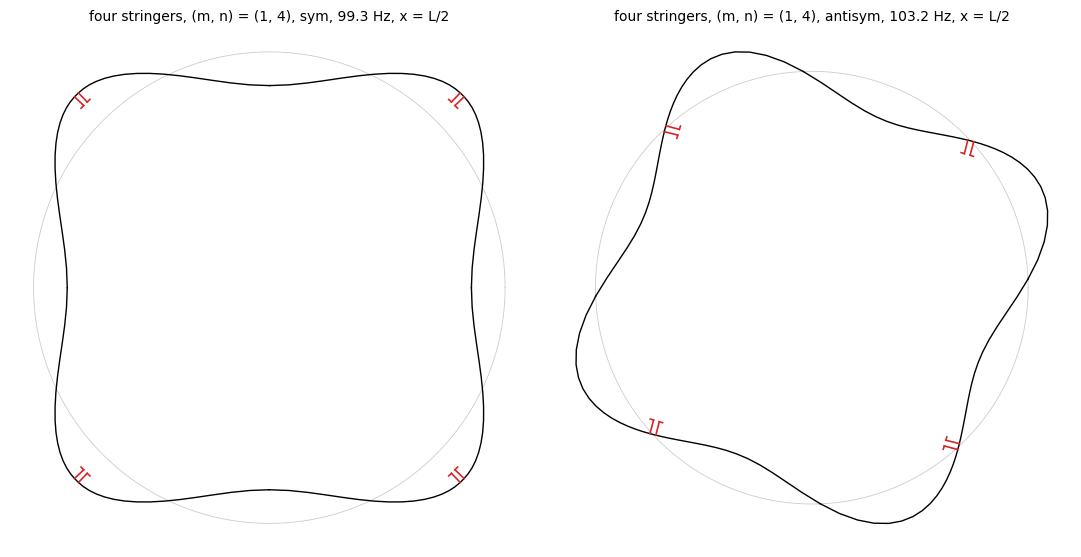

In [20]:
def plot_cross_section(ax, model, mode, j, scale):
    i = model.nx//2
    R = model.R
    u = normalize_phase(mode)
    w = u[DOF*model.skin_nodes[i] + W]
    v = u[DOF*model.skin_nodes[i] + V]
    norm = scale/np.abs(w).max()
    ax.plot(R*np.cos(np.linspace(0, 2*np.pi, 361)),
            R*np.sin(np.linspace(0, 2*np.pi, 361)), color='0.8', lw=0.6)
    for k in range(model.nstringers):
        fac = np.exp(1j*j*k*model.phi)
        th0 = k*model.phi
        r = R + norm*np.real(w*fac)
        th = th0 + model.theta + norm*np.real(v*fac)/R
        ax.plot(r*np.cos(th), r*np.sin(th), 'k', lw=1)
        for s in range(2):
            nodes = model.web_nodes[s][i]
            tw = th0 + model.theta[model.j_webs[s]]
            r0 = R + model.Yweb
            r = r0 + norm*np.real(u[DOF*nodes + V]*fac)
            th = tw + norm*np.real(u[DOF*nodes + W]*fac)/r0
            ax.plot(r*np.cos(th), r*np.sin(th), 'C3', lw=1.2)
            nodes = model.lip_nodes[s][i]
            rl = R + model.Yweb[-1]
            r = rl + norm*np.real(u[DOF*nodes + W]*fac)
            th = tw + (model.Ylip[s] + norm*np.real(u[DOF*nodes + V]*fac))/rl
            ax.plot(r*np.cos(th), r*np.sin(th), 'C3', lw=1.2)
    ax.set_aspect('equal')
    ax.axis('off')


fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, fam in zip(axes, ['sym', 'antisym']):
    d = tabs[4][(1, 4, fam)]
    plot_cross_section(ax, geo[4], d['mode'], d['j'], scale=1.2)
    ax.set_title('four stringers, (m, n) = (1, 4), %s, %.1f Hz, x = L/2'
                 % (fam, d['f']), fontsize=10)
plt.tight_layout()
plt.show()

## Discussion

**The analysis of [1] is reproduced when its assumptions are made.** With
the in-surface inertia of the skin neglected and Donnell-type kinematics
(FE\*D), the model gives column c of Table 3 of [1] within $-0.1$ to
$+0.6$ % (mean $+0.2$ %), and columns a and b, the four-stringer cylinder,
within $-2.6$ to $+1.8$ % (means $+0.6$ % and $+0.1$ %), the largest
differences at $m = 4$, $n = 4$ (antisymmetric, $-2.6$ %) and $m = 3$,
$n = 4$ ($-1.1$ %). The split of the even $n$ into a symmetric and an
antisymmetric frequency is reproduced in size and sign: the symmetric modes
are lower for $m = 1, 2$ and higher for $m = 3, 4$ at $n \ge 8$, as [1]
explains (pages 523 and 524) by the bending of the stringers in the
symmetric modes and their torsion in the antisymmetric modes (the
cross-sections above). The remaining differences come from the stringer
model, which differs in several ways: beams with the properties of Table 1
of [1] against plates (larger area and bending stiffness in the model, see
the section table; lateral bending, warping of the open section and the
deformation of the channel included in the model), the 20-term series of
[1] (page 523), and the reading of $d_s'$ and $\bar{z}_s$ discussed with the
section properties.

**Effect of the two assumptions of [1].** Neglecting the in-surface
inertia raises the frequencies by up to 13 % at $n = 2$ and 5 to 6 % at $n =
3$, less than 2 % for $n \ge 6$ (figure above), as [1] (page 522) expected.
Donnell-type kinematics raise them by up to 2.5 % for $m = 1$, $n = 4$ to
8, the modes with few axial and circumferential waves of this long shell
($L/R = 5.1$). The model with the in-surface inertia and Sanders-type
kinematics (FE), the more complete one, is therefore below Table 3 of [1]:
by $-1.5$ % ($-5.9$ to $+0.6$ %, symmetric) and $-2.0$ % ($-5.9$ to $-0.3$ %,
antisymmetric) for four stringers, $-2.1$ % ($-5.6$ to $-0.6$ %) without
stringers, the most at $n = 3$.

**Tests.** The model is within $-1.4$ to $+4.8$ % of the tests of the
four-stringer cylinder (mean $+1.4$ %), closer than the analysis of [1]
($+2.2$ %, $-1.7$ to $+5.7$ %), mainly at $m = 1$, $n = 5$ to 10, where [1]
is 3 to 4 % above the tests and the model 0 to 3 %: there the in-surface
inertia and the kinematics matter. For eight stringers the model is within
$-2.0$ to $+5.5$ % (mean $+1.7$ %) of the tests read from Figure 4 of [1] and
$-4.4$ to $+4.4$ % (mean $+1.1$ %) of the same tests read from Figure 12 of
[2]; the two readings differ by up to 6 Hz (the largest at $m = 2$, $n = 5$,
243.1 against 237.2 Hz), which is the order of the scatter of the
comparison. The largest differences are above the tests, at $n \ge 9$: up
to +4.8 % at $m = 2$, $n = 9$ to 12 with four stringers, and +5.5 % at
$m = 1$, $n = 11$ with eight (a symbol that overlaps another one in Figure 4
of [1]). Possible sources, none of which can be checked without the report
of the tests (Ref. 8 of [1], Ref. 15 of [2], not consulted):

- how the stringers were attached: the model bonds the base to the skin
  over its whole width and ties the webs rigidly; spot welds or rivets
  would make the joint more flexible. The base itself matters little: the
  model without the base differs by $-2.2$ to $+0.7$ %;
- the realisation of the freely supported ends in the tests (fixtures,
  restraint of the stringer ends), the excitation and the identification
  of $m$ and $n$ of the measured modes, in particular of the symmetric or
  antisymmetric family, which the figures do not give (each test is compared
  with the nearer of the two FE frequencies);
- the dimensions and the material: Table 1 of [1] gives nominal values
  (Figure 12 of [2] rounds them to $R$ = 7.65 in, $h$ = 0.0183 in), and $E$ =
  29.0e6 psi for the steel sheet;
- the reading precision, about $\pm 1$ to 1.5 Hz on the test symbols, 0.5 to
  1.5 % of the frequencies compared.

**Smeared analyses of [2].** The model is close to the smeared analysis of
[2] with the eccentricity of the stringers ("Present paper"), $-1.0$ % on
average, $-5.1$ to $+5.1$ %, the largest differences on the steep parts of
the curves ($n$ = 4 and 5 for $m$ = 2 and 3, where the reading is less
precise), at $m = 4$, $n = 9$ to 11 (about $-4$ %) and at $m = 2$, $n = 12$,
where the curves of Figure 12 of [2] lie
close together. The equivalent shell of Ref. 13 of [2], which does not
account for the eccentricity explicitly, is stiffer: the model is $-6.2$ %
below it on average, down to $-14.3$ % at $m = 4$, $n = 9$; internal
stringers lower the frequencies, more for larger $m$. A smeared analysis
cannot give the two families of the even $n$ (the model is compared with
their mean) nor the coupling of the harmonics, which for eight stringers is
weak (ratios of 0.004 to 0.24 below).

**Section and its idealisation.** The radii of gyration $d_s'$ and $p_s'$ of
Table 1 of [1] are those of the drawing of Figure 12 of [2] about the middle
surface of the skin, consistent with the strain energy of [1], Eq. (5); its
centroid $\bar{z}_s$ = 0.2082 in agrees with the distance from the surface
of the skin (0.2085 in), not from the middle surface (0.2176 in) used by
Eq. (5): either the section of Table 1 is not exactly that of the drawing,
or $\bar{z}_s$ was measured from the surface of the skin, a difference of
$h/2$ (4 %) in the coupling term $\bar{z}_s u_{,x} w_{,xx}$ of [1]. The
torsional stiffness $G \sum b t^3/3$ of the drawing is 6.5 % above that of
Table 1, 11.31 lb in$^2$. These uncertainties of the input of [1] are of the
order of the differences between the model and Table 3 of [1] that remain
with FE\*D.

**Modal coupling.** The model couples the same harmonics as [1], with
ratios of the same order: four stringers, $m = 1$, $n = 4$: 0.047 against
0.0618; $m = 1$, $n = 8$: 0.171 against 0.194; $m = 2$, $n = 9$, coupled to
$n = 5$: 0.550 against 0.720; $m = 2$, $n = 3$, coupled to $n = 15$: 0.186
against 0.247; eight stringers, $m = 1$, $n = 4$: 0.010 against 0.0178;
$m = 1$, $n = 8$: 0.0038 against 0.00228. The mode shapes along the
circumference are those of Figures 5 and 6 of [1]: the mode $m = 2$, $n = 9$
of the four-stringer cylinder has the large component $n = 5$ and the small
displacement at the stringers of the third plot of Figure 5 of [1]. The
frequencies of these modes, from the figures of [1], are within $-3.4$ to
$+0.9$ % of the model. The ratios of [1] come from its Rayleigh-Ritz
coefficients with the in-surface inertia neglected, those of the model from
the numerical Fourier series of $w$, so that only their order and their
pairs are comparable.

**Figure 4 of [1] at $n = 12$.** The largest difference with the theory of
Figure 4 of [1], +9.0 % at $m = 2$, $n = 12$, is a matter of the curves:
the curves read as $m = 1$ and $m = 2$ cross at $n \approx 10.8$, and at
$n = 12$ the curve read as $m = 2$, 390.8 Hz, is within 1.7 % of the model's
symmetric mode $m = 1$, $n = 12$ (397.3 Hz), while the curve read as
$m = 1$ ends near the test at 427 Hz, close to the model's $m = 2$, $n = 12$
(425.8 Hz). In the model the two do not cross. Whether the curves of [1]
cross, or the dominant term of its modes changes there, cannot be decided
from the figure.

## The panels implementation of this case

The panels implementation of this case (the notebook `egle1968_few_stringer_cylinder_vibration` of
panels: whole cylinder with `panels.multidomain`, the base of the channel as a separate cylindrical
panel bonded to the skin, webs and lips as plate strips, Ritz functions) gives the following mean
(min, max) differences (this notebook in brackets):

| reference | panels | bfsccylinder |
|---|---|---|
| Table 3 a, symmetric | −1.7 % (−5.9, +0.6) | −1.5 % (−5.9, +0.6) |
| Table 3 b, antisymmetric | −2.2 % (−5.9, −0.5) | −2.0 % (−5.9, −0.3) |
| Table 3 c, unstiffened | −2.3 % (−5.7, −0.9) | −2.1 % (−5.6, −0.6) |
| Table 3 a/b/c, no in-surface inertia of the skin | −0.4 / −0.8 / −0.7 % | −0.1 / −0.6 / −0.5 % |
| tests of Fig. 3, four stringers | +1.2 % (−1.8, +4.7), closer of sym./antisym. | +1.4 % (−1.4, +4.8) |
| tests of Fig. 4, eight stringers | +1.6 % (−2.2, +5.6) | +1.7 % (−2.0, +5.5) |
| tests of Fig. 12, eight stringers | +0.9 % (−4.6, +4.2) | +1.1 % (−4.4, +4.4) |
| Fig. 12, "Present paper" curve | −1.2 % (−10.2, +6.0) | −1.0 % (−5.1, +5.1) |
| Fig. 12, "Ref. 13 and app. B" curve | −6.4 % (−14.6, +3.3) | −6.2 % (−14.3, +2.4) |

The two implementations agree within 0.3 percentage points on average; panels gives 91.1 Hz for
the four-stringer shell at $(m, n) = (1, 5)$ (Table 3: 94.7 Hz) and 88.7 Hz for the lowest mode of
the eight-stringer shell, $(1, 5)$. Both find the outlier at $(2, 12)$ of Fig. 4. They differ in
two points: the panels section follows the drawing (area +1.6 % against Table 1, +4.4 % here, where
the webs overlap the skin and the base), and panels finds a smaller splitting of the symmetric and
antisymmetric frequencies at even $n$ than Table 3 (e.g. $m = 4$, $n = 4$: −32 Hz against −55 Hz),
while the splitting here matches Table 3 in size and sign; the cause is not established.